# Modelos: leve, grave o mortal

Se usan el CSV limpio y el pipeline ya ajustado en el entrenamiento. No se vuelve a calcular la media ni el escalador. La etiqueta es la gravedad publicada, con sus tres niveles. Los tres modelos llevan el peso de clase guardado. El piso de comparación predice siempre «leve».


In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd()
for candidato in [ROOT, *ROOT.parents]:
    if (candidato / "data" / "siniestros_hechos_limpio.csv").exists():
        ROOT = candidato
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.escala_hora import EscalaHoraSinImputar  # noqa: F401

RUTA = ROOT / "data" / "siniestros_hechos_limpio.csv"
PIPELINE = ROOT / "data" / "preprocesado" / "pipeline.joblib"
PESOS = ROOT / "data" / "preprocesado" / "pesos_clase.json"
FIGURAS = ROOT / "docs" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "mes_siniestro",
    "dia_siniestro",
    "rango_horario",
    "comuna_siniestro",
    "tipo_de_via_siniestro",
    "modo_desplazamiento_victima",
    "contraparte_siniestro",
]
NIVELES = ["LEVE", "GRAVE", "MORTAL"]

df = pd.read_csv(RUTA, sep=";", encoding="utf-8-sig")
X = df[FEATURES].copy()
y = df["gravedad_siniestro"].astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
pipeline = joblib.load(PIPELINE)
pesos_json = json.loads(PESOS.read_text(encoding="utf-8"))
peso = {nivel: pesos_json["pesos"][nivel] for nivel in NIVELES}

X_train_m = pipeline.transform(X_train)
X_test_m = pipeline.transform(X_test)
print("Entrenamiento:", X_train_m.shape, "| prueba:", X_test_m.shape)
print("Pesos:", {nivel: round(peso[nivel], 3) for nivel in NIVELES})
print(y_test.value_counts().reindex(NIVELES).to_string())


Entrenamiento: (52654, 54) | prueba: (13164, 54)
Pesos: {'LEVE': 0.353, 'GRAVE': 7.424, 'MORTAL': 31.854}
gravedad_siniestro
LEVE      12435
GRAVE       591
MORTAL      138


## Hiperparámetros

- Regresión logística: `max_iter=1000`, semilla 42, peso de clase del entrenamiento.
- Árbol: `max_depth=5`, `min_samples_leaf=20`, semilla 42, el mismo peso.
- Random forest: 200 árboles, `max_depth=8`, `min_samples_leaf=10`, semilla 42, el mismo peso.

El piso predice LEVE en todas las filas de prueba. Muestra el acierto de quedarse siempre con el nivel más frecuente.


In [2]:
modelos = {
    "siempre_leve": None,
    "regresion_logistica": LogisticRegression(
        class_weight=peso, max_iter=1000, random_state=42
    ),
    "arbol": DecisionTreeClassifier(
        class_weight=peso, max_depth=5, min_samples_leaf=20, random_state=42
    ),
    "random_forest": RandomForestClassifier(
        class_weight=peso,
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1,
    ),
}

predicciones = {}
for nombre, modelo in modelos.items():
    if modelo is None:
        predicciones[nombre] = np.full(len(y_test), "LEVE")
        continue
    modelo.fit(X_train_m, y_train)
    predicciones[nombre] = modelo.predict(X_test_m)
    print("Ajustado:", nombre)


Ajustado: regresion_logistica
Ajustado: arbol


Ajustado: random_forest


## Cómo se lee cada número

El acierto cuenta bien los tres niveles juntos. Con 94 % de leves, casi todo el acierto sale de ese nivel. El recall de un nivel es la parte de los hechos de ese nivel que el modelo nombró bien. El recall macro es el promedio de los tres recall, sin dejar que el leve tape al grave y al mortal. La elección usa ese promedio.


In [3]:
filas = []
reportes = {}
for nombre, pred in predicciones.items():
    reporte = classification_report(
        y_test, pred, labels=NIVELES, target_names=NIVELES, digits=3, output_dict=True, zero_division=0
    )
    reportes[nombre] = reporte
    filas.append({
        "modelo": nombre,
        "acierto": reporte["accuracy"],
        "recall_macro": reporte["macro avg"]["recall"],
        "f1_macro": reporte["macro avg"]["f1-score"],
        "recall_leve": reporte["LEVE"]["recall"],
        "recall_grave": reporte["GRAVE"]["recall"],
        "recall_mortal": reporte["MORTAL"]["recall"],
        "precision_grave": reporte["GRAVE"]["precision"],
        "precision_mortal": reporte["MORTAL"]["precision"],
        "f1_grave": reporte["GRAVE"]["f1-score"],
        "f1_mortal": reporte["MORTAL"]["f1-score"],
    })
    print("\n", nombre)
    print(classification_report(
        y_test, pred, labels=NIVELES, target_names=NIVELES, digits=3, zero_division=0
    ))

tabla = pd.DataFrame(filas).sort_values(
    ["recall_macro", "recall_mortal", "recall_grave"], ascending=False
)
tabla



 siempre_leve
              precision    recall  f1-score   support

        LEVE      0.945     1.000     0.972     12435
       GRAVE      0.000     0.000     0.000       591
      MORTAL      0.000     0.000     0.000       138

    accuracy                          0.945     13164
   macro avg      0.315     0.333     0.324     13164
weighted avg      0.892     0.945     0.918     13164


 regresion_logistica


              precision    recall  f1-score   support

        LEVE      0.981     0.595     0.741     12435
       GRAVE      0.086     0.503     0.147       591
      MORTAL      0.048     0.754     0.090       138

    accuracy                          0.592     13164
   macro avg      0.372     0.617     0.326     13164
weighted avg      0.931     0.592     0.707     13164




 arbol
              precision    recall  f1-score   support

        LEVE      0.972     0.677     0.798     12435
       GRAVE      0.198     0.193     0.196       591
      MORTAL      0.030     0.848     0.058       138

    accuracy                          0.657     13164
   macro avg      0.400     0.573     0.351     13164
weighted avg      0.928     0.657     0.764     13164


 random_forest


              precision    recall  f1-score   support

        LEVE      0.986     0.548     0.705     12435
       GRAVE      0.082     0.467     0.139       591
      MORTAL      0.041     0.848     0.078       138

    accuracy                          0.548     13164
   macro avg      0.369     0.621     0.307     13164
weighted avg      0.935     0.548     0.673     13164



,modelo,acierto,recall_macro,f1_macro,recall_leve,recall_grave,recall_mortal,precision_grave,precision_mortal,f1_grave,f1_mortal
3,random_forest,0.547706,0.621014,0.307132,0.548211,0.467005,0.847826,0.081609,0.040823,0.138938,0.077896
1,regresion_logistica,0.592221,0.616951,0.325794,0.594692,0.502538,0.753623,0.086037,0.047794,0.146921,0.089888
2,arbol,0.657399,0.572694,0.350520,0.677362,0.192893,0.847826,0.198261,0.029809,0.195540,0.057593
0,siempre_leve,0.944622,0.333333,0.323841,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


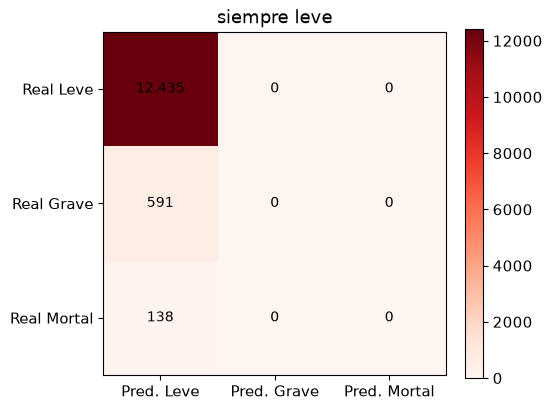

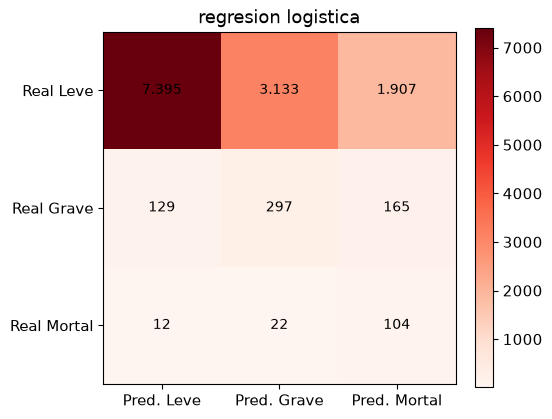

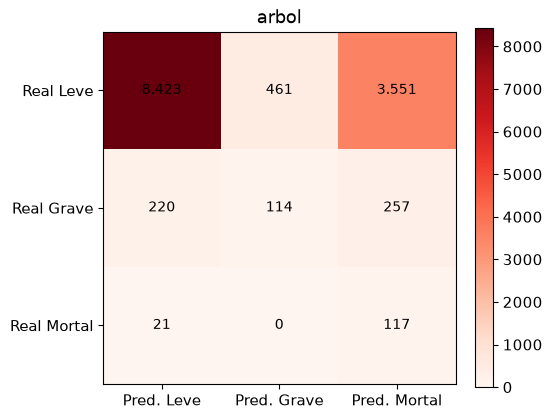

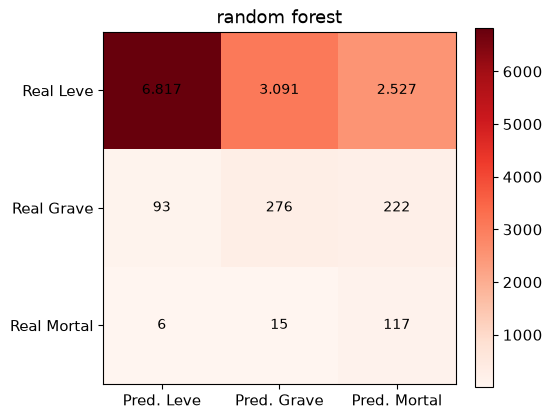

In [4]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
})
ETIQUETAS = ["Leve", "Grave", "Mortal"]

def dibujar_matriz(nombre, pred, archivo):
    matriz = confusion_matrix(y_test, pred, labels=NIVELES)
    figura, eje = plt.subplots(figsize=(5.4, 4.6))
    imagen = eje.imshow(matriz, cmap="Reds")
    eje.set_xticks([0, 1, 2], [f"Pred. {nombre_nivel}" for nombre_nivel in ETIQUETAS])
    eje.set_yticks([0, 1, 2], [f"Real {nombre_nivel}" for nombre_nivel in ETIQUETAS])
    eje.set_title(nombre.replace("_", " "))
    for i in range(3):
        for j in range(3):
            eje.text(
                j, i, f"{matriz[i, j]:,}".replace(",", "."),
                ha="center", va="center", color="black", fontsize=10,
            )
    figura.colorbar(imagen, ax=eje, fraction=0.046)
    figura.tight_layout()
    figura.savefig(FIGURAS / archivo, dpi=140, bbox_inches="tight")
    plt.show()
    return matriz

matrices = {}
for nombre, pred in predicciones.items():
    matrices[nombre] = dibujar_matriz(nombre, pred, f"06_matriz_{nombre}.png").tolist()


## Cuál se queda

Se ordena por el recall macro: el promedio del recall de leve, de grave y de mortal. Si dos empatan, desempata el recall del mortal y después el del grave. El acierto no entra en la elección.


In [5]:
elegido = tabla.iloc[0]["modelo"]
print("Modelo elegido:", elegido)
print(tabla.round(3).to_string(index=False))

salida = {
    "elegido": elegido,
    "clases": NIVELES,
    "criterio": "mayor recall macro en la prueba; desempate por recall del mortal y después del grave",
    "hiperparametros": {
        "regresion_logistica": {"max_iter": 1000, "class_weight": "pesos del entrenamiento", "random_state": 42},
        "arbol": {"max_depth": 5, "min_samples_leaf": 20, "class_weight": "pesos del entrenamiento", "random_state": 42},
        "random_forest": {
            "n_estimators": 200,
            "max_depth": 8,
            "min_samples_leaf": 10,
            "class_weight": "pesos del entrenamiento",
            "random_state": 42,
        },
    },
    "prueba": {
        "filas": int(len(y_test)),
        "por_nivel": {nivel: int((y_test == nivel).sum()) for nivel in NIVELES},
    },
    "modelos": filas,
    "matrices": matrices,
}
ruta = ROOT / "data" / "preprocesado" / "modelos.json"
ruta.write_text(json.dumps(salida, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Guardado en", ruta)


Modelo elegido: random_forest
             modelo  acierto  recall_macro  f1_macro  recall_leve  recall_grave  recall_mortal  precision_grave  precision_mortal  f1_grave  f1_mortal
      random_forest    0.548         0.621     0.307        0.548         0.467          0.848            0.082             0.041     0.139      0.078
regresion_logistica    0.592         0.617     0.326        0.595         0.503          0.754            0.086             0.048     0.147      0.090
              arbol    0.657         0.573     0.351        0.677         0.193          0.848            0.198             0.030     0.196      0.058
       siempre_leve    0.945         0.333     0.324        1.000         0.000          0.000            0.000             0.000     0.000      0.000
Guardado en D:\Cositas\Progra\sistemas-inteligentes-uni\siniestros-viales-predictor\data\preprocesado\modelos.json


## Estructura del modelo elegido

El random forest no es un árbol solo. Cada uno se arma con una muestra del entrenamiento, mira unas pocas columnas en cada corte y se frena por la profundidad y por el tamaño de la hoja. El peso de clase entra al elegir el corte. Para un hecho nuevo, cada árbol devuelve su proporción de leve, grave y mortal. El bosque promedia esas proporciones y se queda con la más alta.

La figura sale del modelo ya ajustado. Si cambian los hiperparámetros, al volver a correr esta celda el dibujo cambia con ellos.


Bosque de 200 árboles. Cada corte mira 7 de 54 columnas. Profundidad máxima 8. Hoja de al menos 10 hechos.
Guardado en D:\Cositas\Progra\sistemas-inteligentes-uni\siniestros-viales-predictor\docs\diagramas\06_bosque.png


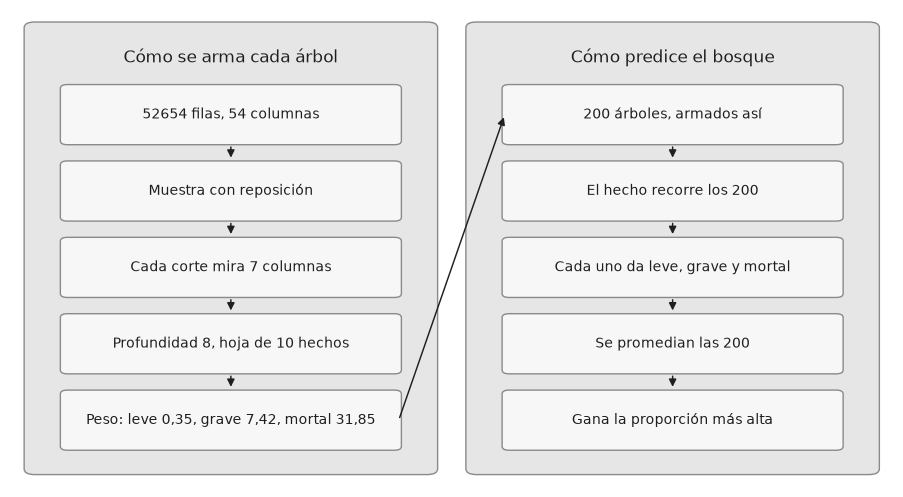

In [6]:
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))
from _estructura_bosque import dibujar_estructura

bosque = modelos[elegido]
ruta_estructura = ROOT / "docs" / "diagramas" / "06_bosque.png"
estructura = dibujar_estructura(
    bosque,
    X_train_m.shape[0],
    X_train_m.shape[1],
    peso,
    ruta_estructura,
)
print(
    "Bosque de {arboles} árboles. Cada corte mira {columnas_por_corte} "
    "de {columnas} columnas. Profundidad máxima {profundidad}. "
    "Hoja de al menos {hoja} hechos.".format(**estructura)
)
print("Guardado en", estructura["archivo"])


## El mismo modelo en 2022-2025 y en 2025

Estas corridas no reemplazan el modelo guardado. `pipeline.joblib` y `modelos.json` siguen siendo los de 2019-2025. En cada ventana se repite el esquema: 80/20 estratificado, semilla 42, y el escalador y el peso se calculan solo con el entrenamiento de esa ventana.

2025 tiene 90 mortales. En la prueba entran cerca de 18. Esa matriz se lee con esa cantidad, no como si tuviera las 138 de la serie completa.


2022-2025: prueba 8357 filas, mortales 82, graves 416
siempre_leve acierto 0.94 recall macro 0.333 grave 0.0 mortal 0.0


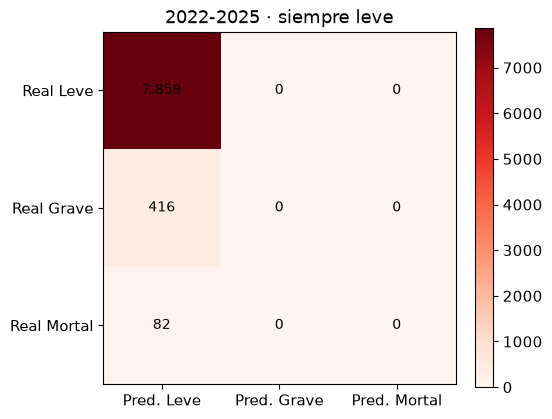

regresion_logistica acierto 0.572 recall macro 0.565 grave 0.471 mortal 0.646


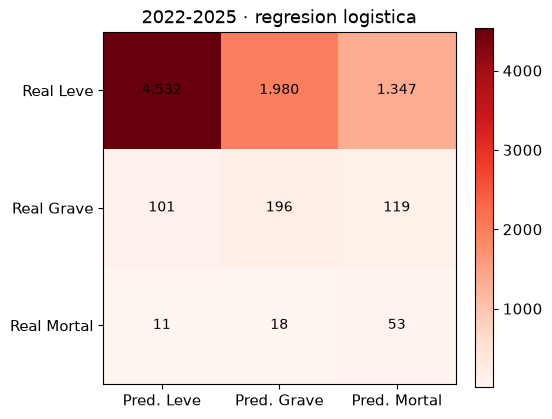

arbol acierto 0.417 recall macro 0.538 grave 0.498 mortal 0.707


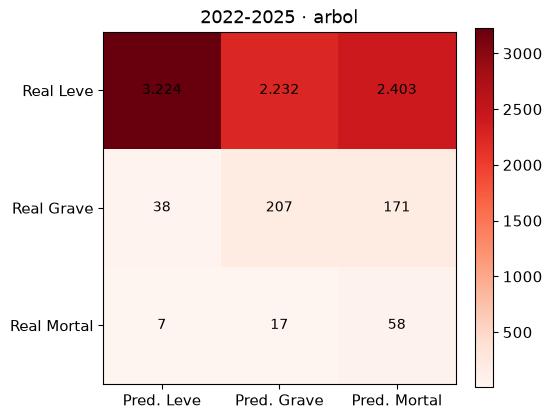

random_forest acierto 0.58 recall macro 0.57 grave 0.44 mortal 0.683


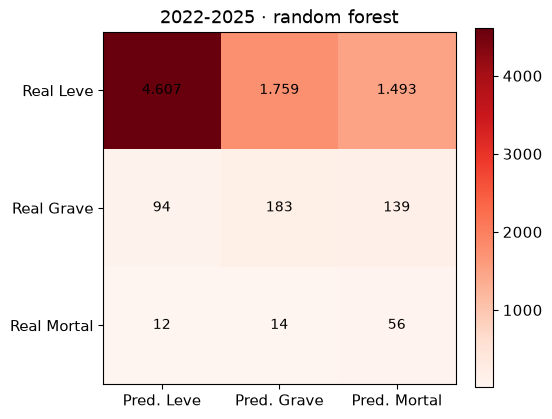


2025: prueba 2351 filas, mortales 18, graves 137
siempre_leve acierto 0.934 recall macro 0.333 grave 0.0 mortal 0.0


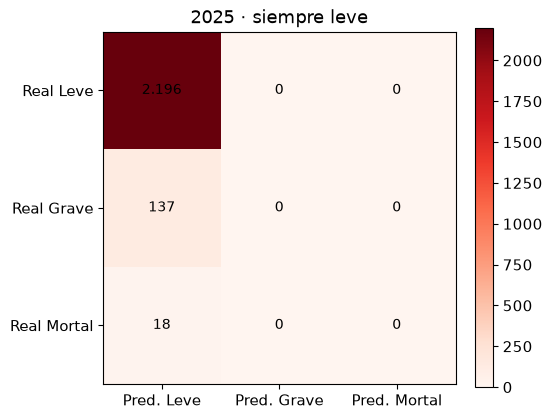

regresion_logistica acierto 0.54 recall macro 0.591 grave 0.511 mortal 0.722


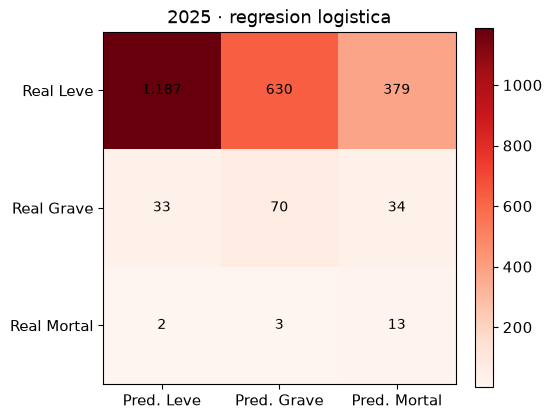

arbol acierto 0.372 recall macro 0.504 grave 0.423 mortal 0.722


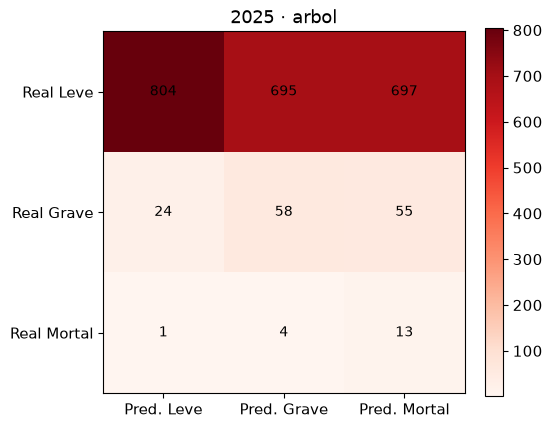

random_forest acierto 0.511 recall macro 0.512 grave 0.526 mortal 0.5


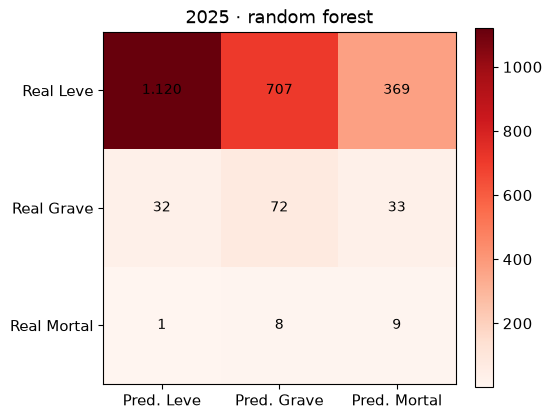

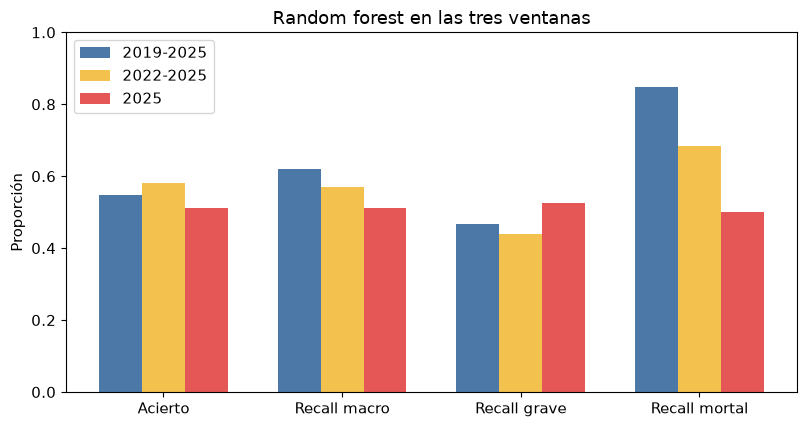

,ventana,modelo,acierto,recall_macro,recall_grave,recall_mortal,mortales_prueba
0,2019-2025,random_forest,0.548,0.621,0.467,0.848,138
1,2022-2025,random_forest,0.580,0.570,0.440,0.683,82
2,2025,random_forest,0.511,0.512,0.526,0.500,18


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight

COLUMNAS_NUM = ["mes_siniestro", "dia_siniestro"]
COLUMNA_HORA = "rango_horario"
COLUMNAS_CAT = [
    "comuna_siniestro",
    "tipo_de_via_siniestro",
    "modo_desplazamiento_victima",
    "contraparte_siniestro",
]
anio = df["anio_siniestro"].astype(int)
ventanas = {
    "2022-2025": df.loc[anio >= 2022].copy(),
    "2025": df.loc[anio == 2025].copy(),
}
prefijos = {"2022-2025": "09_2022_2025", "2025": "10_2025"}


def matriz_de(nombre, y_real, pred, archivo):
    matriz = confusion_matrix(y_real, pred, labels=NIVELES)
    figura, eje = plt.subplots(figsize=(5.4, 4.6))
    imagen = eje.imshow(matriz, cmap="Reds")
    eje.set_xticks([0, 1, 2], [f"Pred. {nivel}" for nivel in ETIQUETAS])
    eje.set_yticks([0, 1, 2], [f"Real {nivel}" for nivel in ETIQUETAS])
    eje.set_title(nombre)
    for i in range(3):
        for j in range(3):
            eje.text(
                j, i, f"{matriz[i, j]:,}".replace(",", "."),
                ha="center", va="center", color="black", fontsize=10,
            )
    figura.colorbar(imagen, ax=eje, fraction=0.046)
    figura.tight_layout()
    figura.savefig(FIGURAS / archivo, dpi=140, bbox_inches="tight")
    plt.show()
    return matriz


comparacion = [
    {
        "ventana": "2019-2025",
        "modelo": "random_forest",
        "acierto": float(tabla.set_index("modelo").loc["random_forest", "acierto"]),
        "recall_macro": float(tabla.set_index("modelo").loc["random_forest", "recall_macro"]),
        "recall_grave": float(tabla.set_index("modelo").loc["random_forest", "recall_grave"]),
        "recall_mortal": float(tabla.set_index("modelo").loc["random_forest", "recall_mortal"]),
        "mortales_prueba": int((y_test == "MORTAL").sum()),
    }
]

for nombre_ventana, parte in ventanas.items():
    Xv = parte[FEATURES].copy()
    yv = parte["gravedad_siniestro"].astype(str)
    X_tr, X_te, y_tr, y_te = train_test_split(
        Xv, yv, test_size=0.2, random_state=42, stratify=yv
    )
    transformador = ColumnTransformer(
        [
            ("calendario", StandardScaler(), COLUMNAS_NUM),
            ("hora", EscalaHoraSinImputar(), [COLUMNA_HORA]),
            (
                "categoricas",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                COLUMNAS_CAT,
            ),
        ]
    )
    X_tr_m = transformador.fit_transform(X_tr)
    X_te_m = transformador.transform(X_te)
    pesos = compute_class_weight("balanced", classes=np.array(NIVELES), y=y_tr)
    peso_ventana = dict(zip(NIVELES, pesos))
    modelos_ventana = {
        "siempre_leve": None,
        "regresion_logistica": LogisticRegression(
            class_weight=peso_ventana, max_iter=1000, random_state=42
        ),
        "arbol": DecisionTreeClassifier(
            class_weight=peso_ventana, max_depth=5, min_samples_leaf=20, random_state=42
        ),
        "random_forest": RandomForestClassifier(
            class_weight=peso_ventana,
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1,
        ),
    }
    print(
        f"\n{nombre_ventana}: prueba {len(y_te)} filas, "
        f"mortales {(y_te == 'MORTAL').sum()}, graves {(y_te == 'GRAVE').sum()}"
    )
    for nombre_modelo, modelo in modelos_ventana.items():
        if modelo is None:
            pred = np.full(len(y_te), "LEVE")
        else:
            modelo.fit(X_tr_m, y_tr)
            pred = modelo.predict(X_te_m)
        reporte = classification_report(
            y_te, pred, labels=NIVELES, target_names=NIVELES, digits=3, output_dict=True, zero_division=0
        )
        print(
            nombre_modelo,
            "acierto", round(reporte["accuracy"], 3),
            "recall macro", round(reporte["macro avg"]["recall"], 3),
            "grave", round(reporte["GRAVE"]["recall"], 3),
            "mortal", round(reporte["MORTAL"]["recall"], 3),
        )
        archivo = f"{prefijos[nombre_ventana]}_matriz_{nombre_modelo}.png"
        matriz_de(f"{nombre_ventana} · {nombre_modelo.replace('_', ' ')}", y_te, pred, archivo)
        if nombre_modelo == "random_forest":
            comparacion.append({
                "ventana": nombre_ventana,
                "modelo": nombre_modelo,
                "acierto": reporte["accuracy"],
                "recall_macro": reporte["macro avg"]["recall"],
                "recall_grave": reporte["GRAVE"]["recall"],
                "recall_mortal": reporte["MORTAL"]["recall"],
                "mortales_prueba": int((y_te == "MORTAL").sum()),
            })

comparacion = pd.DataFrame(comparacion)
figura, eje = plt.subplots(figsize=(8.2, 4.4))
metricas = ["acierto", "recall_macro", "recall_grave", "recall_mortal"]
etiquetas_metricas = ["Acierto", "Recall macro", "Recall grave", "Recall mortal"]
x = np.arange(len(metricas))
ancho = 0.24
colores = ["#4C78A8", "#F2C14E", "#E45756"]
for i, fila in comparacion.iterrows():
    eje.bar(
        x + (i - 1) * ancho,
        [fila[metrica] for metrica in metricas],
        width=ancho,
        color=colores[i],
        label=fila["ventana"],
    )
eje.set_xticks(x, etiquetas_metricas)
eje.set_ylim(0, 1)
eje.set_ylabel("Proporción")
eje.set_title("Random forest en las tres ventanas")
eje.legend()
figura.tight_layout()
figura.savefig(FIGURAS / "09_recorte_comparacion.png", dpi=140, bbox_inches="tight")
plt.show()
comparacion.round(3)
